### **Natural language processing**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [90]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from bs4 import BeautifulSoup
from textblob import TextBlob, Word
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier

### Working with text data

In [126]:
text = "   \tHello, Python!  \n"
print(repr(text.strip()))   # "'Hello, Python!'"

'Hello, Python!'


In [25]:
line = "This  is\ta test\nline."
line.split()  # ['This', 'is', 'a', 'test', 'line.']

['This', 'is', 'a', 'test', 'line.']

In [26]:
csv = "apple,banana, cherry ,date"
fruits = [item.strip() for item in csv.split(",")] # ['apple', 'banana', 'cherry', 'date']
fruits

['apple', 'banana', 'cherry', 'date']

In [27]:
multiline = "first line\nsecond line\r\nthird line"
lines = multiline.splitlines() # ['first line', 'second line', 'third line']
lines

['first line', 'second line', 'third line']

In [28]:
tokens = text.strip().split()
tokens

['Hello,', 'Python!']

#### Regular expressions

| Pattern | Description                         | Example Matches     |
| ------- | ----------------------------------- | ------------------- |
| `\d`    | Any digit (0–9)                     | “3”, “7”            |
| `\D`    | Any non-digit                       | “a”, “@”            |
| `\w`    | “Word” character: letter, digit, \_ | “A”, “z”, “5”, “\_” |
| `\W`    | Any non-word character              | “!”, “ ”            |
| `\s`    | Whitespace: space, tab, newline     | “ ”, `\n`, `\t`     |
| `\S`    | Any non-whitespace                  | “a”, “1”, “.”       |

In [29]:
text = "ID: XYZ_123, Status: OK"
print(re.findall(r"\d+", text))   # ['123']
print(re.findall(r"\w+", text))   # ['ID', 'XYZ_123', 'Status', 'OK']
print(re.findall(r"\S+", text))   # ['ID:', 'XYZ_123,', 'Status:', 'OK']
print(re.findall(r"[A-Za-z0-9']+", text)) # ['ID', 'XYZ', '123', 'Status', 'OK']

['123']
['ID', 'XYZ_123', 'Status', 'OK']
['ID:', 'XYZ_123,', 'Status:', 'OK']
['ID', 'XYZ', '123', 'Status', 'OK']


In [30]:
# Email Address
pattern = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"

emails = "alice@example.com, bob@mail.co.uk, invalid@com"
valid = re.findall(pattern, emails)
valid

['alice@example.com', 'bob@mail.co.uk']

In [197]:
# IPv4 addresses
text_ips = "Servers: 192.168.0.1, 10.0.0.254; invalid: 999.999.999.999"
pattern_ip = r"\b(?:(?:25[0-5]|2[0-4]\d|1?\d?\d)\.){3}(?:25[0-5]|2[0-4]\d|1?\d?\d)\b"

ips = re.findall(pattern_ip, text_ips)
print("IPv4 matches:", ips)

IPv4 matches: ['192.168.0.1', '10.0.0.254']


In [32]:
# URLs
text_urls = "Visit http://example.com or secure https://sub.domain.org/path?x=1. Invalid: ftp://nope"
pattern_url = r"https?://[^\s/$.?#].[^\s]*"
urls = re.findall(pattern_url, text_urls)
print("URL matches:", urls)

URL matches: ['http://example.com', 'https://sub.domain.org/path?x=1.']


In [33]:
# Hex color codes
text_hex = "Colors: #FF5733, #0f0, #123ABC, bad: #GGGGGG"
pattern_hex = r"#[0-9A-Fa-f]{6}\b"
hexes = re.findall(pattern_hex, text_hex)
print("Hex matches:", hexes)

Hex matches: ['#FF5733', '#123ABC']


In [34]:
# Simple dates (YYYY-MM-DD)
text_dates = "Deadlines: 2026-06-15, 1999-12-31; bad: 2026-6-5, 20-01-01"
pattern_date = r"\b\d{4}-\d{2}-\d{2}\b"
dates = re.findall(pattern_date, text_dates)
print("Date matches:", dates)

Date matches: ['2025-06-15', '1999-12-31']


#### Natural Language Toolkit (nltk)

In [35]:
# Download the “Punkt” tokenizer models used by NLTK for sentence and word tokenization
nltk.download("punkt")            # run once

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/tsitsitepnadze/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

* Punkt is an unsupervised machine-learning–based tokenizer

* It learns sentence boundaries from text (e.g. where a sentence ends)

* Supports multiple languages

| Feature              | `.split()` | Punkt |
| -------------------- | ---------- | ----- |
| Sentence detection   | -          | ✓     |
| Abbreviations        | -          | ✓     |
| Punctuation handling | -          | ✓     |
| Language awareness   | -          | ✓     |
| NLP-ready            | -          | ✓     |

In [101]:
text = "Hello, world! It's 2026."
tokens = word_tokenize(text) # ['Hello', ',', 'world', '!', 'It', "'s", '2026', '.']
tokens

['Hello', ',', 'world', '!', 'It', "'s", '2026', '.']

In [102]:
text = "Dr. Smith lives in the U.S. He works at Google."
sent_tokenize(text)

['Dr. Smith lives in the U.S.', 'He works at Google.']

In [103]:
text.split(".")

['Dr', ' Smith lives in the U', 'S', ' He works at Google', '']

In [104]:
raw = "  This is a test—of simple text processing in Python!  "
clean = raw.strip()
by_whitespace = clean.split()
by_regex = re.findall(r"\w+", clean)
by_nltk = word_tokenize(clean)

print("clean      ", clean)
print("whitespace ", by_whitespace)
print("regex      ", by_regex)
print("nltk       ", by_nltk)

clean       This is a test—of simple text processing in Python!
whitespace  ['This', 'is', 'a', 'test—of', 'simple', 'text', 'processing', 'in', 'Python!']
regex       ['This', 'is', 'a', 'test', 'of', 'simple', 'text', 'processing', 'in', 'Python']
nltk        ['This', 'is', 'a', 'test—of', 'simple', 'text', 'processing', 'in', 'Python', '!']


### Twitter Sentiment Analysis

In [192]:
df_train = pd.read_csv("../../datasets/twitter_sentiment/train.csv")
df_test = pd.read_csv("../../datasets/twitter_sentiment/test.csv")

df_train.head()

,id,label,tweet
0,1,0,@user when a father is dysfunctional and is s...
1,2,0,@user @user thanks for #lyft credit i can't us...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in ...
4,5,0,factsguide: society now #motivation


In [155]:
df_test.head()

,id,tweet
0,31963,#studiolife #aislife #requires #passion #dedic...
1,31964,@user #white #supremacists want everyone to s...
2,31965,safe ways to heal your #acne!! #altwaystohe...
3,31966,is the hp and the cursed child book up for res...
4,31967,"3rd #bihday to my amazing, hilarious #nephew..."


In [156]:
# Count number of words
def num_of_words(df):
    df["word_count"] = df["tweet"].apply(lambda x : len(str(x).split(" ")))
    return df[["tweet", "word_count"]].head()

num_of_words(df_train)

,tweet,word_count
0,@user when a father is dysfunctional and is s...,21
1,@user @user thanks for #lyft credit i can't us...,22
2,bihday your majesty,5
3,#model i love u take with u all the time in ...,17
4,factsguide: society now #motivation,8


In [157]:
# Count number of characters
def num_of_chars(df):
    df["char_count"] = df["tweet"].str.len() ## this also includes spaces
    return df[["tweet", "char_count"]].head()

num_of_chars(df_train)

,tweet,char_count
0,@user when a father is dysfunctional and is s...,102
1,@user @user thanks for #lyft credit i can't us...,122
2,bihday your majesty,21
3,#model i love u take with u all the time in ...,86
4,factsguide: society now #motivation,39


In [158]:
# Average word length
def avg_word(sentence):
    words = sentence.split()    
    return (sum(len(word) for word in words)/len(words))
    
def avg_word_length(df):
    df["avg_word"] = df["tweet"].apply(lambda x: avg_word(x))
    return df[["tweet", "avg_word"]].head()

avg_word_length(df_train)

,tweet,avg_word
0,@user when a father is dysfunctional and is s...,4.555556
1,@user @user thanks for #lyft credit i can't us...,5.315789
2,bihday your majesty,5.666667
3,#model i love u take with u all the time in ...,4.928571
4,factsguide: society now #motivation,8.000000


In [159]:
stop = stopwords.words("english")
set(stopwords.words("english"))

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [160]:
# Number of stopwords
def stop_words(df):
    df["stopwords"] = df["tweet"].apply(lambda x: len([x for x in x.split() if x in stop]))
    return df[["tweet", "stopwords"]].head()

stop_words(df_train)

,tweet,stopwords
0,@user when a father is dysfunctional and is s...,10
1,@user @user thanks for #lyft credit i can't us...,5
2,bihday your majesty,1
3,#model i love u take with u all the time in ...,5
4,factsguide: society now #motivation,1


In [161]:
# Number of special characters
def hash_tags(df):
    df["hashtags"] = df["tweet"].apply(lambda x: len([x for x in x.split() if x.startswith("#")]))
    return df[["tweet", "hashtags"]].head()

hash_tags(df_train)

,tweet,hashtags
0,@user when a father is dysfunctional and is s...,1
1,@user @user thanks for #lyft credit i can't us...,3
2,bihday your majesty,0
3,#model i love u take with u all the time in ...,1
4,factsguide: society now #motivation,1


In [162]:
# Number of numerics
def num_numerics(df):
    df["numerics"] = df["tweet"].apply(lambda x: len([x for x in x.split() if x.isdigit()]))
    return df[["tweet", "numerics"]].head()

num_numerics(df_train)

,tweet,numerics
0,@user when a father is dysfunctional and is s...,0
1,@user @user thanks for #lyft credit i can't us...,0
2,bihday your majesty,0
3,#model i love u take with u all the time in ...,0
4,factsguide: society now #motivation,0


#### Basic Text Processing  

| Step               | Why / When to Use                                                                                          |
| -------------------- | ---------------------------------------------------------------------------------------------------------- |
| Lowercasing          | ნორმალიზება: “Bad”, “bad”, “BAD” → “bad”. თითქმის ყოველთვის რეკომენდებულია.                                |
| Removing HTML tags   | თუ ტექსტი შეიცავს HTML კომპონენტებს.                                                     |
| Removing URLs        | URL-ები მცირე ემოციას ატარებს, შეიძლება ასევე უბრალოდ ჩავანაცვლოთ <URL>-ით.                                      |
| Removing punctuation | წმენდს “happy!!!” → “happy”. თუმცა პუნქტუაცია ტონს გამოხატავს და მისი ჩამოშორებით ეს გვეკარგება.                                               |
| Chat-Words Treatment | სლენგი, შემოკლებული სიტყვები ჩანაცვლდება (“u” → “you”, “gr8” → “great”), თუმცა ამისთვის გვჭირდება slang dictionary.                    |
| Spelling Correction  | TYPO-ებს აშორებს (“goood” → “good”), vectorizer ერთ ტოკენს განიხილავს. თუმცა დიდი დრო სჭირდება და ზოგჯერ over-correct-ის პრობლემა აქვს.         |
| Removing Stop-Words  | ძალიან გავრცელებული სიტყვების (“the”, “is”) ამოშლა.                     |
| Handling Emojis      | Emojis ემოციას უფრო კარგად გამოხატავენ, ვიდრე სიტყვები. შეგვიძლია გადავსახოთ ტოკენებში: `:smile:` → “happy”. |
| Tokenization         | ტექსტის დაყოფა სიტყვებად/ქვესიტყვებად.  |
| Stemming | აგრესიული დაჭრა (“running” → “run”), ამცირებს vocabulary-ს. |
| Lemmatization | სიტყვებს გარდაქმნის ფუძისეულ სიტყვად (“better” → “good”, “running” → “run”). |


თუ გვაქვს ML pipeline (მაგ: TF-IDF + Logistic Regression), უნდა გავაკეთოთ:
* Lowercase
* Remove URLs/HTML/punctuation (or at least normalize)
* Tokenize
* (Optionally) remove stop words
* (Optionally) stem or lemmatize

In [198]:
# Sample text
text = ("<p>Hey! I luv this movie!!! Check it out: http://example.com 😊 gr8 experience, "
        "but teh ending was meh… #disappointed</p>")

# Lowercase
step1 = text.lower()

# Remove HTML tags
step2 = re.sub(r"<.*?>", " ", step1)

# Remove URLs
step3 = re.sub(r"http\S+|www\.\S+", " ", step2)

# Remove punctuation 
step4 = re.sub(r"[^\w\s]", " ", step3)

# Chat-words treatment
chat_dict = {"luv": "love", "gr8": "great", "meh": "mediocre", "u": "you"}
tokens = step4.split()
step5 = " ".join(chat_dict.get(w, w) for w in tokens)

# Spelling correction
step6 = TextBlob(step5).correct()

# Remove stop-words
tokens = [w for w in step6.split() if w not in stop]
step7 = " ".join(tokens)

print("Original:      ", text)
print("Lowercased:    ", step1)
print("No HTML:       ", step2)
print("No URLs:       ", step3)
print("No Punct.:     ", step4)
print("Chat words →:  ", step5)
print("Spelling →:    ", step6)
print("No stop-words: ", step7)

Original:       <p>Hey! I luv this movie!!! Check it out: http://example.com 😊 gr8 experience, but teh ending was meh… #disappointed</p>
Lowercased:     <p>hey! i luv this movie!!! check it out: http://example.com 😊 gr8 experience, but teh ending was meh… #disappointed</p>
No HTML:         hey! i luv this movie!!! check it out: http://example.com 😊 gr8 experience, but teh ending was meh… #disappointed 
No URLs:         hey! i luv this movie!!! check it out:   😊 gr8 experience, but teh ending was meh… #disappointed 
No Punct.:       hey  i luv this movie    check it out      gr8 experience  but teh ending was meh   disappointed 
Chat words →:   hey i love this movie check it out great experience but teh ending was mediocre disappointed
Spelling →:     hey i love this movie check it out great experience but the ending was mediocre disappointed
No stop-words:  hey love movie check great experience ending mediocre disappointed


In [199]:
print(tokens)

['hey', 'love', 'movie', 'check', 'great', 'experience', 'ending', 'mediocre', 'disappointed']


* Stemming removes word endings to get a base form, often not a real word, but useful for NLP
* run, running, runs → run

In [200]:
# Stemming
stemmer = PorterStemmer()
stemmed_tokens = [stemmer.stem(tok) for tok in tokens]
stemmed_tokens

['hey',
 'love',
 'movi',
 'check',
 'great',
 'experi',
 'end',
 'mediocr',
 'disappoint']

* Lemmatization reduces a word to a real
* running → run, better → good, mice → mouse

In [201]:
# Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_tokens = [lemmatizer.lemmatize(tok) for tok in tokens]
lemmatized_tokens

['hey',
 'love',
 'movie',
 'check',
 'great',
 'experience',
 'ending',
 'mediocre',
 'disappointed']

| Feature       | Stemming                | Lemmatization   |
| ------------- | ----------------------- | --------------- |
| Output        | Root form (may be fake) | Real word       |
| Speed         | Fast                    | Slower          |
| Needs grammar | No                      | Yes             |
| Example       | studies → studi         | studies → study |

In [167]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|<.*?>|@\w+", "", text)            # URLs, HTML, mentions
    text = re.sub(r"#(\w+)", r"\1", text)                     # strip “#” but keep the word
    text = re.sub(r"[^\w\s]", " ", text)                      # drop punctuation but keep colon for emojis
    tokens = word_tokenize(text)                              # word-level tokenization
    return " ".join(tokens)

In [168]:
df_train["tweet"] = df_train["tweet"].apply(preprocess)
df_test["tweet"] = df_test["tweet"].apply(preprocess)

In [169]:
# Stop Words Removal
df_train["tweet"] = df_train["tweet"].apply(lambda x: " ".join(x for x in x.split() if x not in stop))
df_test["tweet"] = df_test["tweet"].apply(lambda x: " ".join(x for x in x.split() if x not in stop))

In [170]:
# Frequent Words Removal 
freq_words = pd.Series(" ".join(df_train["tweet"]).split()).value_counts()[:10]
freq_words = list(freq_words.index)
df_train["tweet"] = df_train["tweet"].apply(lambda x: " ".join(x for x in x.split() if x not in freq_words))
df_test["tweet"] = df_test["tweet"].apply(lambda x: " ".join(x for x in x.split() if x not in freq_words))

### Converting text to feature

In [171]:
# Converting text to feature using One Hot Encoding
text = "This is the first document"
tokenize_words = text.split()
pd.get_dummies(tokenize_words).astype(int)

,This,document,first,is,the
0,1,0,0,0,0
1,0,0,0,1,0
2,0,0,0,0,1
3,0,0,1,0,0
4,0,1,0,0,0


CountVectorization (a “Bag-of-Words” model) არის მარტივი გზა ტექსტის numeric feature matrix-ად გარდაქმნისათვის.

Bag-of-Words intuition
1. Ignore order: თითოეული დოკუმენტი განიხილება როგორც სიტყვათა “ჩანთა”.

2. Build a vocabulary: ყველა უნიკალური სიტყვა (token) შეგროვდება ყველა დოკუმენტიდან. 

3. Count occurrences: თითოეული დოკუმენტისთვის ითვლება, რამდენჯერ გვხვდება თითო სიტყვა (token).

4. Vector space: დოკუმენტი წარმოდგინდება ვექტორის სახით, რომლის კომპონენტები არიან სიტყვების სიხშირე.

---

`CountVectorizer`

1. Pre-processing & tokenization
2. Vocabulary building
3. Document-term matrix
4. Hyperparameters

   * `min_df` / `max_df`: იშორებს ძალიან იშვიათ ან ძალიან გავრცელებულ ტოკენებს.
   * `ngram_range=(1,2)`: აძლევს უნიგრამებისა და ბიგრამების გამოყენებას.
   * `stop_words="english"`: აცილებს stop_words.
   * `max_features`: აბრუნებს მხოლოდ ყველაზე ხშირ ტოპ-K ტოკენს.

---

In [172]:
corpus = [
          "This is the first document.",
          "This document is the second document.",
          "And this is the third one.",
          "Is this the first document?",
         ]

In [173]:
# Tokenization (lowercase + regex)
tokenized = [re.findall(r"\b\w+\b", doc.lower()) for doc in corpus]
tokenized

[['this', 'is', 'the', 'first', 'document'],
 ['this', 'document', 'is', 'the', 'second', 'document'],
 ['and', 'this', 'is', 'the', 'third', 'one'],
 ['is', 'this', 'the', 'first', 'document']]

In [174]:
# Build vocabulary (unique sorted tokens)
vocab = sorted({token for doc in tokenized for token in doc})
vocab

['and', 'document', 'first', 'is', 'one', 'second', 'the', 'third', 'this']

In [175]:
# Count occurrences for each document
data = []
for doc in tokenized:
    counts = {term: doc.count(term) for term in vocab}
    data.append(counts)
data

[{'and': 0,
  'document': 1,
  'first': 1,
  'is': 1,
  'one': 0,
  'second': 0,
  'the': 1,
  'third': 0,
  'this': 1},
 {'and': 0,
  'document': 2,
  'first': 0,
  'is': 1,
  'one': 0,
  'second': 1,
  'the': 1,
  'third': 0,
  'this': 1},
 {'and': 1,
  'document': 0,
  'first': 0,
  'is': 1,
  'one': 1,
  'second': 0,
  'the': 1,
  'third': 1,
  'this': 1},
 {'and': 0,
  'document': 1,
  'first': 1,
  'is': 1,
  'one': 0,
  'second': 0,
  'the': 1,
  'third': 0,
  'this': 1}]

In [176]:
# Create DataFrame (documents × vocabulary)
df_counts = pd.DataFrame(data, index=[f"Doc{i+1}" for i in range(len(corpus))], columns=vocab)
df_counts

,and,document,first,is,one,second,the,third,this
Doc1,0,1,1,1,0,0,1,0,1
Doc2,0,2,0,1,0,1,1,0,1
Doc3,1,0,0,1,1,0,1,1,1
Doc4,0,1,1,1,0,0,1,0,1


In [177]:
# CountVectorization
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(corpus)
pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=["Doc1", "Doc2", "Doc3", "Doc4"]) # სტრიქონები – დოკუმენტები; სვეტები – სიტყვები; მნიშვნელობები – სიხშირეები.

,and,document,first,is,one,second,the,third,this
Doc1,0,1,1,1,0,0,1,0,1
Doc2,0,2,0,1,0,1,1,0,1
Doc3,1,0,0,1,1,0,1,1,1
Doc4,0,1,1,1,0,0,1,0,1


In [178]:
vectorizer2 = CountVectorizer(analyzer="word", ngram_range=(2, 2))
X = vectorizer2.fit_transform(corpus)
print(vectorizer2.get_feature_names_out())

['and this' 'document is' 'first document' 'is the' 'is this'
 'second document' 'the first' 'the second' 'the third' 'third one'
 'this document' 'this is' 'this the']


TF–IDF (Term Frequency–Inverse Document Frequency)

1. Term Frequency (TF)

ტერმინთა სიხშირე ზომავს, რამდენად ხშირად ჩანს ტერმინი $t$ დოკუმენტში $d$ და ითვლება ასე:

$$
\mathrm{TF}(t,d) = \frac{\text{ტერმინი }t\text{-ის რაოდენობა დოკუმენტში }d}{\text{დოკუმენტში სიტყვათა ჯამი}}
$$

---

2. Inverse Document Frequency (IDF)

IDF აძლევს ტერმინებს, რომლებიც ხშირად ფიგურირებენ კონკრეტულ დოკუმენტში, უფრო დაბალ წონებს (down-weights):

$$
\mathrm{IDF}(t) = \log\!\Bigl(\frac{N}{\mathrm{DF}(t)}\Bigr)
$$

$$
\mathrm{IDF}_{\text{smooth}}(t) = \log\!\Bigl(\frac{1 + N}{1 + \mathrm{DF}(t)}\Bigr) + 1
$$

* $N$ — დოკუმენტთა საერთო რაოდენობა
* $\mathrm{DF}(t)$ — დოკუმენტების რაოდენობა, სადაც ტერმინი $t$ გვხვდება

---

3. TF–IDF Weight

$d$ დოკუმენტში $t$ ტერმინის TF–IDF წონა არის:

$$
\mathrm{TF\text{–}IDF}(t,d) = \mathrm{TF}(t,d) \times \mathrm{IDF}(t)
$$

ეს ანიჭებს დიდ წონებს ტერმინებს, რომლებიც ხშირად გვხვდებიან კონკრეტულ დოკუმენტში, მაგრამ იშვიათია სხვა დოკუმენტებში.

---

4. Normalization

Raw TF–IDF ვექტორები ხშირად ნორმალიზდება L2 ნორმით, რათა სხვადასხვა სიგრძის დოკუმენტებს გავლენა არ ჰქონდეთ:

$$
\mathbf{v}_d \;\leftarrow\; \frac{\mathbf{v}_d}{\|\mathbf{v}_d\|_2}
$$

---

`TfidfVectorizer`

1. Preprocessing & tokenization

2. Builds vocabulary

3. Computes term counts or raw TF

4. Computes IDF

5. Forms TF–IDF matrix

6. ძირითადი პარამეტრები

* `ngram_range=(1,2)` – უნიგრამები და ბიგრამები.
* `min_df`, `max_df` – იშორებს ზედმეტად იშვიათ ან ძალიან ხშირ ტოკენებს.
* `use_idf` – set `False` to disable IDF - მიიღებთ მხოლოდ TF.
* `smooth_idf` – IDF–ის გლუვი ვერსია.
* `sublinear_tf` – გამოიყენება $1+\log(\mathrm{TF})$.
* `norm` – ვექტორის ნორმალიზაცია (`'l2'` by default).

---

In [202]:
# Preprocessing & tokenization
tokenized = [re.findall(r"\b\w+\b", doc.lower()) for doc in corpus]
tokenized

[['this', 'is', 'the', 'first', 'document'],
 ['this', 'document', 'is', 'the', 'second', 'document'],
 ['and', 'this', 'is', 'the', 'third', 'one'],
 ['is', 'this', 'the', 'first', 'document']]

In [203]:
# Build vocabulary
vocab = sorted({token for doc in tokenized for token in doc})
vocab

['and', 'document', 'first', 'is', 'one', 'second', 'the', 'third', 'this']

In [204]:
# Compute document frequency (DF)
N = len(corpus)
doc_frec = {term: sum(1 for doc in tokenized if term in doc) for term in vocab}
doc_frec

{'and': 1,
 'document': 3,
 'first': 2,
 'is': 4,
 'one': 1,
 'second': 1,
 'the': 4,
 'third': 1,
 'this': 4}

In [205]:
# Compute IDF (smooth)
idf = {term: float(np.log((1 + N) / (1 + df_t)) + 1) for term, df_t in doc_frec.items()}
idf

{'and': 1.916290731874155,
 'document': 1.2231435513142097,
 'first': 1.5108256237659907,
 'is': 1.0,
 'one': 1.916290731874155,
 'second': 1.916290731874155,
 'the': 1.0,
 'third': 1.916290731874155,
 'this': 1.0}

In [206]:
# Compute TF (raw counts)
tf = []
for doc in tokenized:
    counts = {term: doc.count(term) for term in vocab}
    tf.append(counts)
tf

[{'and': 0,
  'document': 1,
  'first': 1,
  'is': 1,
  'one': 0,
  'second': 0,
  'the': 1,
  'third': 0,
  'this': 1},
 {'and': 0,
  'document': 2,
  'first': 0,
  'is': 1,
  'one': 0,
  'second': 1,
  'the': 1,
  'third': 0,
  'this': 1},
 {'and': 1,
  'document': 0,
  'first': 0,
  'is': 1,
  'one': 1,
  'second': 0,
  'the': 1,
  'third': 1,
  'this': 1},
 {'and': 0,
  'document': 1,
  'first': 1,
  'is': 1,
  'one': 0,
  'second': 0,
  'the': 1,
  'third': 0,
  'this': 1}]

In [207]:
# Compute raw TF-IDF
tfidf_raw = []
for doc_tf in tf:
    tfidf_raw.append({term: doc_tf[term] * idf[term] for term in vocab})
tfidf_raw

[{'and': 0.0,
  'document': 1.2231435513142097,
  'first': 1.5108256237659907,
  'is': 1.0,
  'one': 0.0,
  'second': 0.0,
  'the': 1.0,
  'third': 0.0,
  'this': 1.0},
 {'and': 0.0,
  'document': 2.4462871026284194,
  'first': 0.0,
  'is': 1.0,
  'one': 0.0,
  'second': 1.916290731874155,
  'the': 1.0,
  'third': 0.0,
  'this': 1.0},
 {'and': 1.916290731874155,
  'document': 0.0,
  'first': 0.0,
  'is': 1.0,
  'one': 1.916290731874155,
  'second': 0.0,
  'the': 1.0,
  'third': 1.916290731874155,
  'this': 1.0},
 {'and': 0.0,
  'document': 1.2231435513142097,
  'first': 1.5108256237659907,
  'is': 1.0,
  'one': 0.0,
  'second': 0.0,
  'the': 1.0,
  'third': 0.0,
  'this': 1.0}]

In [209]:
# Normalize (L2) each TF-IDF vector
tfidf_norm = []
for doc in tfidf_raw:
    vec = np.array(list(doc.values()))
    norm = np.linalg.norm(vec)
    norm = norm if norm != 0 else 1.0
    tfidf_norm.append({term: float(val / norm) for term, val in zip(vocab, vec)})
tfidf_norm

[{'and': 0.0,
  'document': 0.46979138557992045,
  'first': 0.5802858236844359,
  'is': 0.38408524091481483,
  'one': 0.0,
  'second': 0.0,
  'the': 0.38408524091481483,
  'third': 0.0,
  'this': 0.38408524091481483},
 {'and': 0.0,
  'document': 0.6876235979836938,
  'first': 0.0,
  'is': 0.281088674033753,
  'one': 0.0,
  'second': 0.5386476208856763,
  'the': 0.281088674033753,
  'third': 0.0,
  'this': 0.281088674033753},
 {'and': 0.511848512707169,
  'document': 0.0,
  'first': 0.0,
  'is': 0.267103787642168,
  'one': 0.511848512707169,
  'second': 0.0,
  'the': 0.267103787642168,
  'third': 0.511848512707169,
  'this': 0.267103787642168},
 {'and': 0.0,
  'document': 0.46979138557992045,
  'first': 0.5802858236844359,
  'is': 0.38408524091481483,
  'one': 0.0,
  'second': 0.0,
  'the': 0.38408524091481483,
  'third': 0.0,
  'this': 0.38408524091481483}]

In [210]:
# Display results
df_counts = pd.DataFrame(tf, index=[f"Doc{i+1}" for i in range(N)])
df_idf = pd.Series(idf, name="IDF")
df_tfidf = pd.DataFrame(tfidf_norm, index=[f"Doc{i+1}" for i in range(N)])
df_tfidf

,and,document,first,is,one,second,the,third,this
Doc1,0.000000,0.469791,0.580286,0.384085,0.000000,0.000000,0.384085,0.000000,0.384085
Doc2,0.000000,0.687624,0.000000,0.281089,0.000000,0.538648,0.281089,0.000000,0.281089
Doc3,0.511849,0.000000,0.000000,0.267104,0.511849,0.000000,0.267104,0.511849,0.267104
Doc4,0.000000,0.469791,0.580286,0.384085,0.000000,0.000000,0.384085,0.000000,0.384085


In [211]:
# TfidfVectorizer
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)
pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=["Doc1", "Doc2", "Doc3", "Doc4"])

,and,document,first,is,one,second,the,third,this
Doc1,0.000000,0.469791,0.580286,0.384085,0.000000,0.000000,0.384085,0.000000,0.384085
Doc2,0.000000,0.687624,0.000000,0.281089,0.000000,0.538648,0.281089,0.000000,0.281089
Doc3,0.511849,0.000000,0.000000,0.267104,0.511849,0.000000,0.267104,0.511849,0.267104
Doc4,0.000000,0.469791,0.580286,0.384085,0.000000,0.000000,0.384085,0.000000,0.384085


* Use CountVectorizer when:
    - Dataset is small
    - Model handles frequency well
    - Interpretability matters

* Use TfidfVectorizer when:
    - Doing classification or clustering
    - Using linear models (LogReg, SVM)
    - Words repeat across many documents
    - You want better generalization

In [212]:
df_train["label"].value_counts()

label
0    29720
1     2242
Name: count, dtype: int64

In [213]:
# Feature Extraction
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.9, # Drop a term if it appears in more than 90% of documents (too common words)
    min_df=5, # Remove terms appearing in <5 documents (remove noise)
    ngram_range=(1,2)
)

# გამოვყოთ სატრენინგო/სატესტო მახასიათებლების სიმრავლე და სამიზნე ცვლადი
X_train = vectorizer.fit_transform(df_train["tweet"])
X_test  = vectorizer.transform(df_test ["tweet"])
y_train = df_train["label"]

In [214]:
# გამოვყოთ ვალიდაციის სიმრავლე
X_tr, X_val, y_tr, y_val = train_test_split(df_train["tweet"], y_train, test_size=0.2, random_state=42)

In [215]:
# შევქმნათ Pipeline
pipeline = Pipeline([
    ("tfidf", vectorizer),
    ("xgb", XGBClassifier(
        use_label_encoder=False,   
        eval_metric="mlogloss",   
        n_jobs=-1
    ))
])

pipeline.fit(X_tr, y_tr)

,steps,"[('tfidf', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [216]:
# პროგნოზი და ევალუაციის მეტრიკები ვალიდაციის სიმრავლისთვის
y_pred = pipeline.predict(X_val)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97      5937
           1       0.83      0.40      0.54       456

    accuracy                           0.95      6393
   macro avg       0.90      0.70      0.76      6393
weighted avg       0.95      0.95      0.94      6393



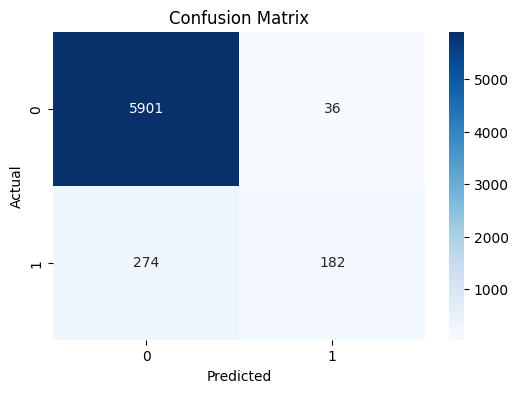

In [217]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_val, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [218]:
# პროგნოზი სატესტო მონაცემებზე
df_test["predicted_sentiment"] = pipeline.predict(df_test["tweet"])

### Email Spam Classification

In [195]:
# მონაცემების წაკითხვა
df_spam = pd.read_csv("../../datasets/spam/emails.csv")
df_spam.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [84]:
# მახასიათებლების (X) და სამიზნის (y) გამოყოფა
X = df_spam.iloc[:, 1:3001]
y = df_spam.iloc[:, -1]
y.value_counts()

Prediction
0    3672
1    1500
Name: count, dtype: int64

In [85]:
# მონაცემთა გაყოფა სასწავლო (80%) და სატესტო (20%) ნაწილებად
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)

In [86]:
# მოდელის გაწვრთნა
model = XGBClassifier(use_label_encoder=False, eval_metric="mlogloss", n_jobs=-1)
model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [87]:
# პროგნოზი
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.97      0.98       734
           1       0.94      0.98      0.96       301

    accuracy                           0.97      1035
   macro avg       0.96      0.97      0.97      1035
weighted avg       0.97      0.97      0.97      1035



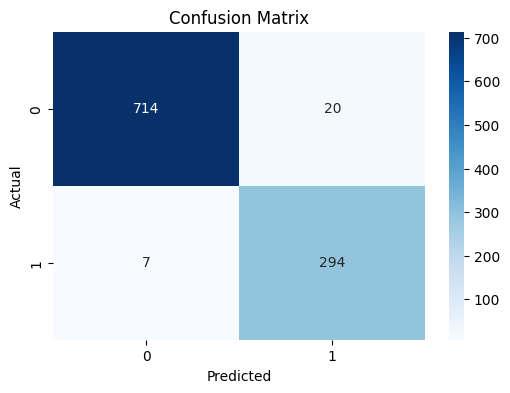

In [88]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### IMDB Reviews

In [123]:
df_imdb = pd.read_csv("../../datasets/imdb/IMDB.csv")
df_imdb.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [132]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    # Decode HTML entities & strip HTML tags
    text = html.unescape(text)
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # Remove non-letters (keep spaces)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    # Lowercase & collapse whitespace
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)
    # Tokenize, remove stop-words, lemmatize
    tokens = []
    for w in text.split():
        if w not in stop_words and len(w) > 2:
            tokens.append(lemmatizer.lemmatize(w))
    return " ".join(tokens)

# Apply to your DataFrame
df_imdb["clean_review"] = df_imdb["review"].apply(clean_text)

In [133]:
# CountVectorizer
bow_vect = CountVectorizer(
    ngram_range=(1,1),   # unigrams only
    min_df=5,            # drop tokens in fewer than 5 docs
    max_df=0.8           # drop tokens in >80% of docs
)

X_bow = bow_vect.fit_transform(df_imdb["clean_review"])
print("BoW vocabulary size:", len(bow_vect.vocabulary_))

BoW vocabulary size: 32039


In [135]:
# TfidfVectorizer
tfidf_vect = TfidfVectorizer(
    ngram_range=(1,2),   # include unigrams & bigrams
    min_df=5,
    max_df=0.8,
    smooth_idf=True
)

X_tfidf = tfidf_vect.fit_transform(df_imdb["clean_review"])
print("TF-IDF vocabulary size:", len(tfidf_vect.vocabulary_))

TF-IDF vocabulary size: 176233


In [138]:
# Map labels to 0/1
df_imdb["y"] = df_imdb["sentiment"].map({"negative": 0, "positive": 1})

# მონაცემთა გაყოფა სასწავლო (80%) და სატესტო (20%) ნაწილებად
X_train, X_test, y_train, y_test = train_test_split(df_imdb["clean_review"], df_imdb["y"], test_size=0.2, random_state=42)

In [139]:
# შევქმნათ Pipeline: Clean the raw text -> Extract TF-IDF features -> Classifier
pipeline = Pipeline([
    ("cleaner", FunctionTransformer(lambda texts: texts.apply(clean_text))),
    ("tfidf", TfidfVectorizer(
        ngram_range=(1,2),
        min_df=5,
        max_df=0.8
    )),
    ("clf", LogisticRegression(max_iter=1000))
])

# Train
pipeline.fit(X_train, y_train)

Pipeline(steps=[('cleaner',
                 FunctionTransformer(func=<function <lambda> at 0x307c35360>)),
                ('tfidf',
                 TfidfVectorizer(max_df=0.8, min_df=5, ngram_range=(1, 2))),
                ('clf', LogisticRegression(max_iter=1000))])

In [141]:
# პროგნოზი
y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.88      0.90      4961
           1       0.89      0.91      0.90      5039

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



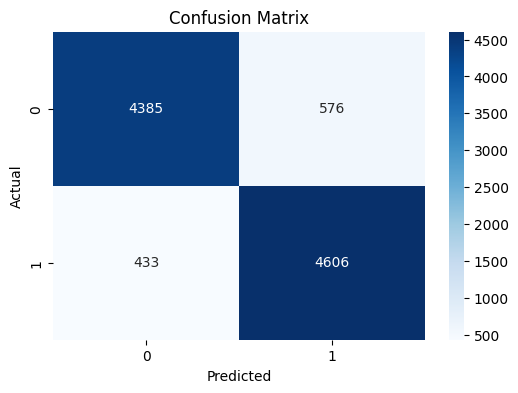

In [142]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()